In [12]:
## Imports ##
from astropy.io import fits
import numpy as np
import glob
import matplotlib.pyplot as plt
from astropy.modeling.functional_models import Gaussian2D

In [13]:
def strip_SIP(header):
    A_prefixes = [i for i in header.keys() if i.startswith('A_')]
    B_prefixes = [i for i in header.keys() if i.startswith('B_')]
    for a,b in zip(A_prefixes,B_prefixes):
        del header[a]
        del header[b]
    return header


def implot(image,figsize=(15,13),cmap='gray_r',scale=0.5,colorbar=False,header=None,wcs=None,**kwargs):
    '''
    Plot an astronomical image, setting default options and easy tweaking of parameters
    
    Parameters
    ----------
    image: array_like
        2D array containing an astronomical image to be plotted. Cutouts should be input as cutout.data.
    figsize: tuple, optional
        figure size to use. Default: (15,13)
    cmap: str, optional
        Colormap to use for the image. Default: 'gray_r'
    scale: float, optional
        By default, function will scale image to some number of standard deviations about the mean pixel value. Scale sets this number (or fraction). Default: 0.5.
    colorbar: bool, optional
        Whether to add a colorbar or not. Default: False
    header: dict, optional
        If input, function will attempt to create a WCS object from header and plot in celestial coordinates. Default: None
    wcs: WCS object
        If input, the function will plot using a projection set by the WCS. Default: None
    **kwargs
        Additional arguments are passed to matplotlib plotting commands. Currently supported: vmin, vmax.
        
    Returns
    -------
    fig, ax
        figure and axes objects containing currently plotted data.
    '''
    if (header==None) and (wcs==None):
        fig, ax = plt.subplots(figsize=figsize)
    elif wcs is not None:
        fig, ax = plt.subplots(figsize=figsize,subplot_kw={'projection':wcs})
        ax.set_xlabel('Right Ascension [hms]',fontsize=15)
        ax.set_ylabel('Declination [degrees]',fontsize=15)
        ax.coords.grid(color='gray', alpha=0.5, linestyle='solid')
    elif header is not None:
        wcs = WCS(header)
        fig, ax = plt.subplots(figsize=figsize,subplot_kw={'projection':wcs})
        ax.set_xlabel('Right Ascension [hms]',fontsize=15)
        ax.set_ylabel('Declination [degrees]',fontsize=15)
        ax.coords.grid(color='gray', alpha=0.5, linestyle='solid')
    mu = np.mean(image)
    s = np.std(image)
    dvmin = mu - scale*s
    dvmax = mu + scale*s
    if all(['vmin','vmax']) in kwargs.keys():
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=kwargs['vmin'],vmax=kwargs['vmax'])
    elif 'vmin' in kwargs.keys():
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=kwargs['vmin'],vmax=dvmax)
    elif 'vmax' in kwargs.keys():
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=dvmin,vmax=kwargs['vmax'])
    else:
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=dvmin,vmax=dvmax)
    if colorbar:
        cbar = plt.colorbar(im,ax=ax)
    ax.tick_params(direction='in',length=9,width=1.5,labelsize=15)
    
    return fig, ax


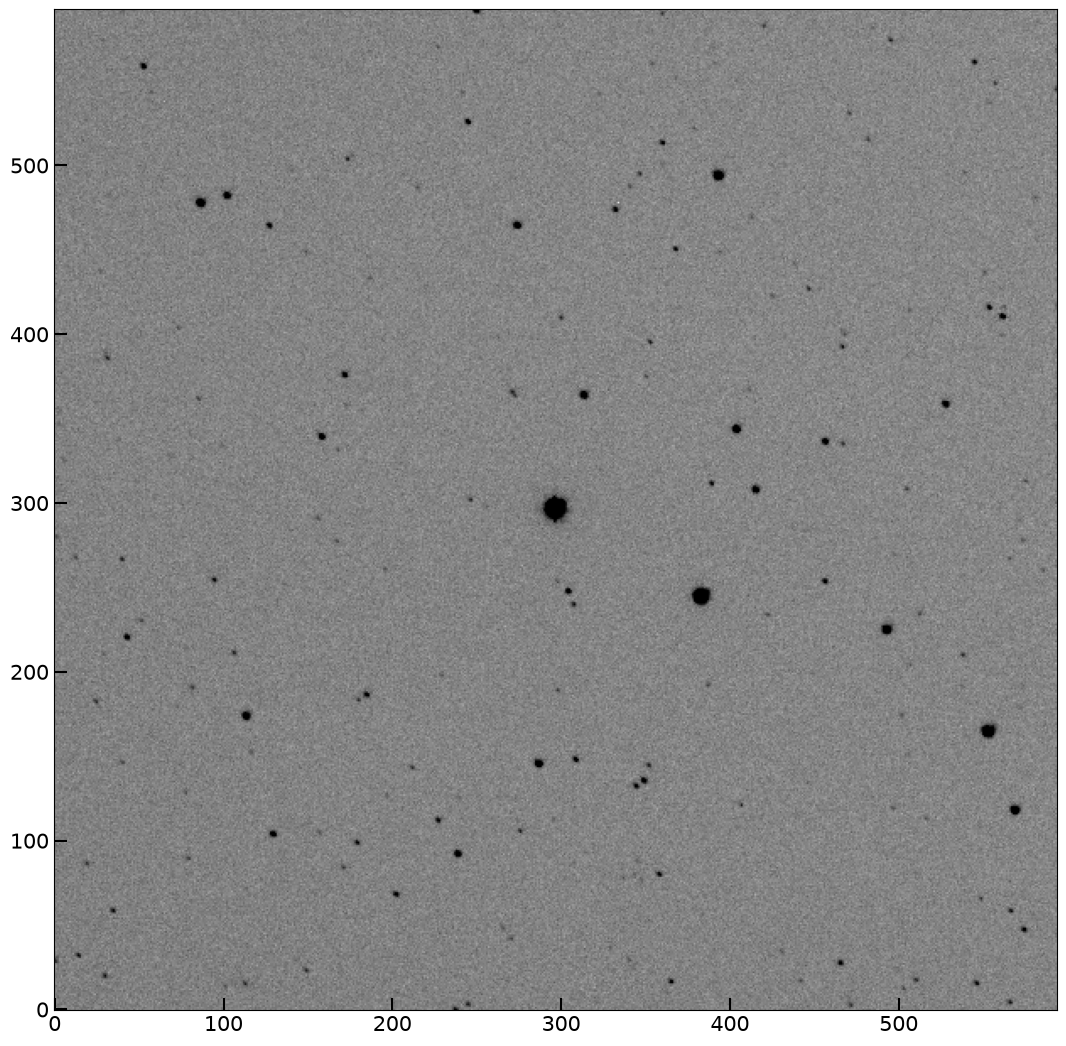

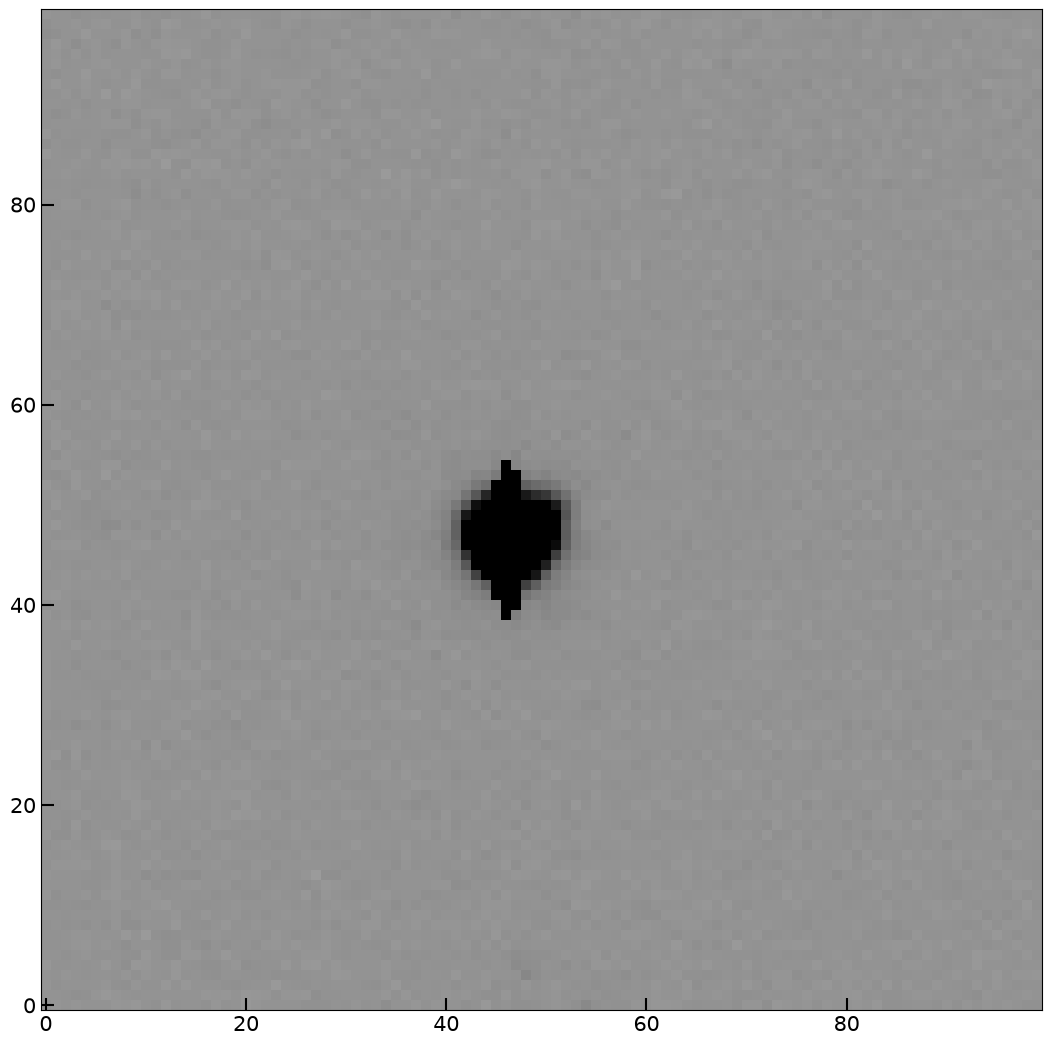

In [99]:
orb = fits.open('image_ZTF-sci-20180331471019-zg-size-600.0arcsec.fits')
crystal = orb[0].data
gem = crystal[250:350,250:350]
# Star @ [300,300]
implot(crystal)
plt.savefig("ica13_fullview.png")
implot(gem)
plt.savefig('ica13_smallview.png')

# The central star is ~40 pixels large on each side #

In [31]:
xvals, yvals = np.meshgrid(np.arange(250,350),np.arange(250,350))

In [43]:
## Define Gaussian2D function ##
def gauss2d(x,y,x_std,y_std,x_mean,y_mean):
    '''
    A function that requires 6 inputs which are floats, used the calculate a 2d Gaussian func.

    Parameters
    -------
    x, y: lowkey not sure, look at ICA #13 for guidance...
        values of a meshgrid the size of your aperature
    x_std, y_std: float or int
        the width of your gaussian (σ) in x and y, use the width of the aperature
    x_mean, y_mean: float or int
        the centroid of the star you are looking at
    '''
    return Gaussian2D.evaluate(x,y, amplitude = 1, x_mean = x_mean, y_mean = y_mean, x_stddev = x_std, y_stddev = y_std, theta = 0)

In [44]:
plot = gauss2d(xvals, yvals, 100, 100, 300,300)

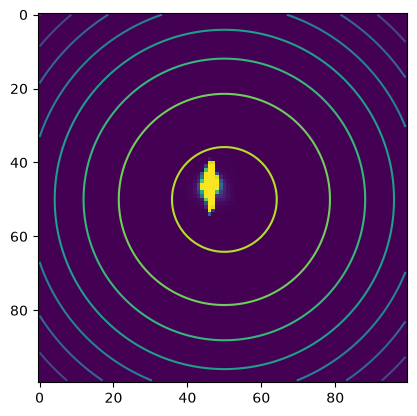

In [100]:
plt.imshow(gem)
plt.contour(plot)
plt.savefig('ica13_centroid_withcontour.png')

In [52]:
convolve = gem * plot
summ = int(np.sum(convolve))

In [53]:
print(summ)

49852034


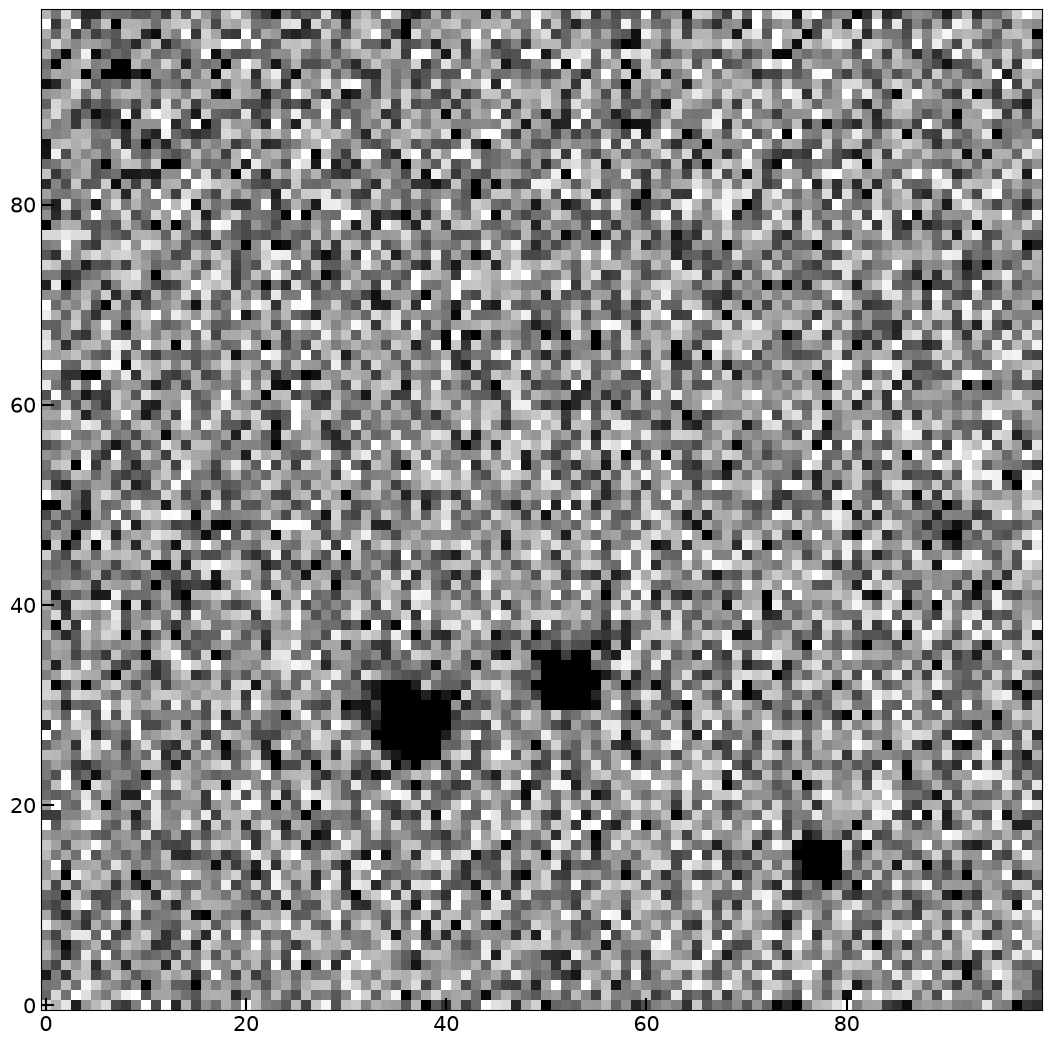

In [101]:
shard = crystal[450:550, 50:150]
implot(shard)
plt.savefig("ica13_blankskypatch.png")

In [82]:
skygauss = gauss2d(xvals,yvals,100,100, 450, 100)

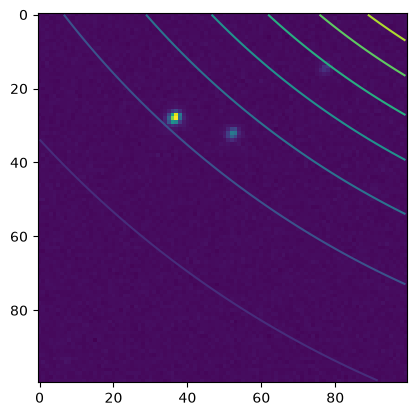

In [102]:
## Code to show model and image of blank patch of sky ##
plt.imshow(shard)
plt.contour(skygauss)
plt.savefig("ica13_blanksky_withcontour.png")

In [85]:
## Calculates median sky count of blank sky ##
medsky = np.median(skygauss)
print(medsky)

0.04123573764701105


In [87]:
## Calculating net star counts ##
def netstar(Nstar, n, Nskymed):
    '''
    A function that takes three parameters and outputs the net star counts of an image.

    Parameters:
    -------
    Nstar: float or int
        total number of counts in the aperature
    n: int
        number of pixels in the aperature
    Nskymed: float or int
        the median number of star counts in a blank sky picture
    '''
    return Nstar-(n*Nskymed)

In [92]:
## Net star counts of centroid ##
nets = netstar(summ, (1500*1300), medsky)
print(nets)

49771624.31158833


In [94]:
## Calculates instrumental magnitude of a star ##
def instmag(net_star, t):
    return -2.5*(np.log10(net_star/t))

In [98]:
## VALUE FOR INST. MAG ##
instmag(nets, 30)

np.float64(-15.549651398959266)

In [103]:
instrument_mag = -15.549651398959266